# PRODIGY_DS_05 — Traffic Accident Analysis (US Accidents)
**Prodigy InfoTech — Data Science Internship, Task 05**

```
PRODIGY_DS_05
--------------
Task: Analyze traffic accident data to identify patterns related to road
conditions, weather, and time of day. Visualize accident hotspots and
contributing factors.

Dataset: US Accidents (Moosavi et al.), a countrywide traffic accident
dataset. By default this script uses accidents_sample.csv, a 10,000-row
sample of the March 2023 version. To run on the full Kaggle file instead,
set DATA_PATH to it and SAMPLE_FRAC to something like 0.01 (the full file
has ~7.7M rows, so sample it rather than loading everything).

NOTE ON "SEVERITY": in this dataset, Severity (1-4) measures the IMPACT ON
TRAFFIC (1 = short delay, 4 = long delay). It is NOT an injury or fatality
scale.
```

> ⚠️ **Read the limitations at the bottom.** The 10,000-row sample used here is *not* representative of the full dataset, and none of the findings show cause and effect.

## 0. Setup
Downloads the 10,000-row sample so the notebook runs on its own. If that URL ever stops working, upload `accidents_sample.csv` from the GitHub repo using Colab's file panel instead.

In [1]:
import os
os.makedirs("output", exist_ok=True)
!wget -q -O accidents_sample.csv "https://raw.githubusercontent.com/vasilis6194/US-Accidents-Project/main/3.%20Data%20Cleaning/cleaned_accidents.csv~d9f7ee01e052b2e1270507a7aaf8808015087adf"
!wc -l accidents_sample.csv

10001 accidents_sample.csv


## Imports & settings

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

DATA_PATH = "accidents_sample.csv"
SAMPLE_FRAC = None  # e.g. 0.01 for the full Kaggle file; None = use every row
RANDOM_STATE = 42

USE_COLS = [
    "ID", "Severity", "Start_Time", "Start_Lat", "Start_Lng", "City", "State",
    "Weather_Condition", "Visibility(mi)", "Sunrise_Sunset",
    "Junction", "Crossing", "Traffic_Signal", "Stop", "Railway", "Give_Way",
    "Roundabout", "Bump", "Amenity", "Station", "No_Exit", "Traffic_Calming",
]
ROAD_FEATURES = ["Junction", "Crossing", "Traffic_Signal", "Stop", "Railway",
                 "Give_Way", "Station", "Amenity"]
DAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

## 1. Load Data

In [3]:
def load_data(path, sample_frac=None):
    """Read only the columns we need, in chunks, optionally sampling rows."""
    parts = []
    for chunk in pd.read_csv(path, usecols=USE_COLS, chunksize=200_000):
        if sample_frac:
            chunk = chunk.sample(frac=sample_frac, random_state=RANDOM_STATE)
        parts.append(chunk)
    return pd.concat(parts, ignore_index=True)


df = load_data(DATA_PATH, SAMPLE_FRAC)
print("Raw shape:", df.shape)

Raw shape: (10000, 22)


## 2. Data Cleaning

In [4]:
print("\n" + "=" * 50)
print("DATA CLEANING")
print("=" * 50)

n0 = len(df)

# 2a. Parse timestamps. The file mixes formats (some with nanoseconds,
# some without), so format="mixed" is needed.
df["Start_Time"] = pd.to_datetime(df["Start_Time"], format="mixed", errors="coerce")

# 2b. Drop rows missing the fields every analysis depends on
before = len(df)
df = df.dropna(subset=["Start_Time", "Start_Lat", "Start_Lng", "Severity"])
print(f"Rows dropped for missing time/location/severity: {before - len(df)}")

# 2c. Drop duplicate accident IDs
before = len(df)
df = df.drop_duplicates(subset="ID")
print(f"Duplicate IDs dropped: {before - len(df)}")

# 2d. Unknown weather -> "Unknown" so those rows aren't silently lost
df["Weather_Condition"] = df["Weather_Condition"].fillna("Unknown")

# 2e. Road-feature flags: make sure they are real booleans
for col in ROAD_FEATURES + ["Roundabout", "Bump"]:
    df[col] = df[col].fillna(False).astype(bool)

print(f"Rows kept: {len(df):,} of {n0:,}")
print("Missing values left in analysis columns:",
      int(df[["Start_Time", "Start_Lat", "Start_Lng", "Severity", "State"]].isnull().sum().sum()))

# 2f. Feature engineering: time-based fields
df["hour"] = df["Start_Time"].dt.hour
df["day_name"] = df["Start_Time"].dt.day_name()
df["is_weekend"] = df["day_name"].isin(["Saturday", "Sunday"])
df["severe"] = df["Severity"] >= 3  # 3-4 = larger traffic impact


def time_bucket(h):
    if h <= 5:
        return "Night (12-6am)"
    if h <= 9:
        return "Morning rush (6-10am)"
    if h <= 14:
        return "Midday (10am-3pm)"
    if h <= 18:
        return "Afternoon rush (3-7pm)"
    return "Evening (7pm-12am)"


BUCKET_ORDER = ["Night (12-6am)", "Morning rush (6-10am)", "Midday (10am-3pm)",
                "Afternoon rush (3-7pm)", "Evening (7pm-12am)"]
df["time_bucket"] = df["hour"].apply(time_bucket)


# 2g. Group the many raw weather strings into a few categories.
# Order matters: check the rarer/more specific conditions first
# (e.g. "Light Freezing Rain" must count as Snow/Ice, not Rain).
def weather_group(w):
    w = str(w).lower()
    if w == "unknown" or "n/a" in w:
        return "Unknown"
    if any(k in w for k in ["snow", "sleet", "ice", "freezing", "hail", "wintry"]):
        return "Snow / Ice"
    if any(k in w for k in ["rain", "drizzle", "storm", "thunder", "shower", "squall"]):
        return "Rain / Storm"
    if any(k in w for k in ["fog", "mist", "haze", "smoke", "dust", "sand"]):
        return "Fog / Haze / Smoke"
    if any(k in w for k in ["cloud", "overcast"]):
        return "Cloudy"
    if any(k in w for k in ["fair", "clear"]):
        return "Clear / Fair"
    return "Other"


df["weather_group"] = df["Weather_Condition"].apply(weather_group)
print("\nWeather grouping (rows per group):\n", df["weather_group"].value_counts())

# Contiguous-US filter for the map only (drops any AK/HI/outlier points)
us = df[df["Start_Lng"].between(-125, -66) & df["Start_Lat"].between(24, 50)]
print(f"Points inside contiguous-US map window: {len(us):,} of {len(df):,}")

footer = f"n = {len(df):,} accidents (US Accidents dataset)"


def add_footer(fig, note=None):
    fig.text(0.99, 0.005, footer, ha="right", va="bottom", fontsize=8, color="gray")
    if note:
        fig.text(0.01, 0.005, note, ha="left", va="bottom", fontsize=8,
                 color="#444444", style="italic")


DATA CLEANING
Rows dropped for missing time/location/severity: 0
Duplicate IDs dropped: 0
Rows kept: 10,000 of 10,000
Missing values left in analysis columns: 0

Weather grouping (rows per group):
 weather_group
Clear / Fair          4917
Cloudy                3682
Rain / Storm           804
Fog / Haze / Smoke     297
Snow / Ice             294
Unknown                  6
Name: count, dtype: int64
Points inside contiguous-US map window: 10,000 of 10,000


## 3. Time Of Day


TIME PATTERNS

Busiest hour: 17:00 (788 accidents)
Share of accidents between 3pm and 7pm: 29.6%
Share of accidents between 12am and 6am: 11.5%


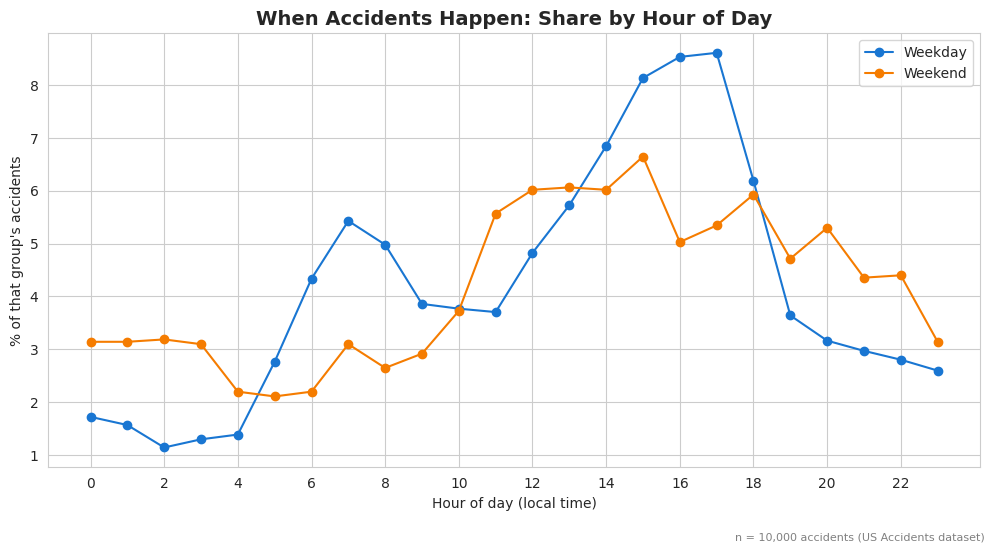

Saved output/accidents_by_hour.png
Weekday peak hour: 17:00 | Weekend peak hour: 15:00
Share of weekday accidents between 12am and 4am: 5.7% | weekend: 12.6%
Accidents on weekdays: 7,773 | weekends: 2,227

Accidents by day:
 day_name
Monday       1366
Tuesday      1498
Wednesday    1581
Thursday     1623
Friday       1705
Saturday     1180
Sunday       1047
Name: count, dtype: int64
Avg per weekday: 1555 | avg per weekend day: 1114


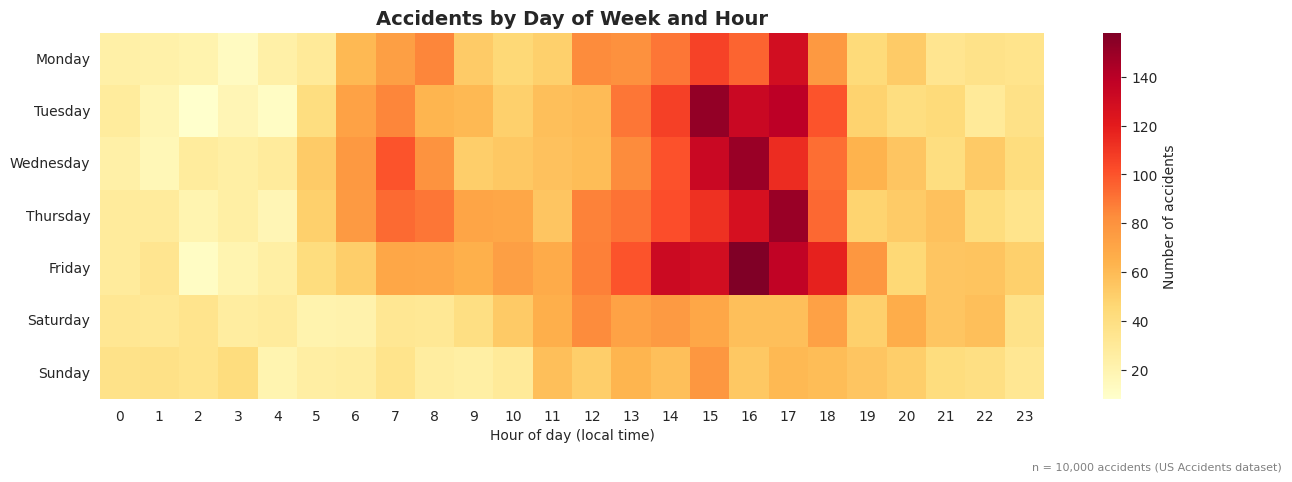

Saved output/day_hour_heatmap.png


In [5]:
print("\n" + "=" * 50)
print("TIME PATTERNS")
print("=" * 50)

by_hour = df["hour"].value_counts().reindex(range(24), fill_value=0)
peak_hour = int(by_hour.idxmax())
print(f"\nBusiest hour: {peak_hour}:00 ({by_hour.max()} accidents)")
aft = by_hour.loc[15:18].sum() / len(df) * 100
print(f"Share of accidents between 3pm and 7pm: {aft:.1f}%")
night = by_hour.loc[0:5].sum() / len(df) * 100
print(f"Share of accidents between 12am and 6am: {night:.1f}%")

# 3a. Accidents by hour — weekday vs weekend (each line sums to 100%)
hourly_share = (
    df.groupby(["is_weekend", "hour"]).size().unstack(0).reindex(range(24), fill_value=0)
)
hourly_share = hourly_share / hourly_share.sum() * 100
hourly_share.columns = ["Weekday", "Weekend"]

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(hourly_share.index, hourly_share["Weekday"], marker="o", label="Weekday", color="#1976D2")
ax.plot(hourly_share.index, hourly_share["Weekend"], marker="o", label="Weekend", color="#F57C00")
ax.set_title("When Accidents Happen: Share by Hour of Day", fontsize=14, fontweight="bold")
ax.set_xlabel("Hour of day (local time)")
ax.set_ylabel("% of that group's accidents")
ax.set_xticks(range(0, 24, 2))
ax.legend()
add_footer(fig)
plt.tight_layout(rect=[0, 0.035, 1, 1])
plt.savefig("output/accidents_by_hour.png", dpi=150)
plt.show()
print("Saved output/accidents_by_hour.png")

wk_peak = int(hourly_share["Weekday"].idxmax())
we_peak = int(hourly_share["Weekend"].idxmax())
print(f"Weekday peak hour: {wk_peak}:00 | Weekend peak hour: {we_peak}:00")
wk_late = hourly_share.loc[0:3, "Weekday"].sum()
we_late = hourly_share.loc[0:3, "Weekend"].sum()
print(f"Share of weekday accidents between 12am and 4am: {wk_late:.1f}% | weekend: {we_late:.1f}%")
print(f"Accidents on weekdays: {int((~df['is_weekend']).sum()):,} | weekends: {int(df['is_weekend'].sum()):,}")

# 3b. Day of week
by_day = df["day_name"].value_counts().reindex(DAY_ORDER)
print("\nAccidents by day:\n", by_day)
wkday_avg = by_day.loc[DAY_ORDER[:5]].mean()
wkend_avg = by_day.loc[DAY_ORDER[5:]].mean()
print(f"Avg per weekday: {wkday_avg:.0f} | avg per weekend day: {wkend_avg:.0f}")

# 3c. Heatmap: day x hour
heat = df.groupby(["day_name", "hour"]).size().unstack(fill_value=0).reindex(DAY_ORDER)
plt.figure(figsize=(13, 4.8))
sns.heatmap(heat, cmap="YlOrRd", cbar_kws={"label": "Number of accidents"})
plt.title("Accidents by Day of Week and Hour", fontsize=14, fontweight="bold")
plt.xlabel("Hour of day (local time)")
plt.ylabel("")
add_footer(plt.gcf())
plt.tight_layout(rect=[0, 0.035, 1, 1])
plt.savefig("output/day_hour_heatmap.png", dpi=150)
plt.show()
print("Saved output/day_hour_heatmap.png")

## 4. Weather


WEATHER

Accidents by weather group (%):
 weather_group
Clear / Fair          49.2
Cloudy                36.8
Rain / Storm           8.0
Fog / Haze / Smoke     3.0
Snow / Ice             2.9
Unknown                0.1
Name: count, dtype: float64


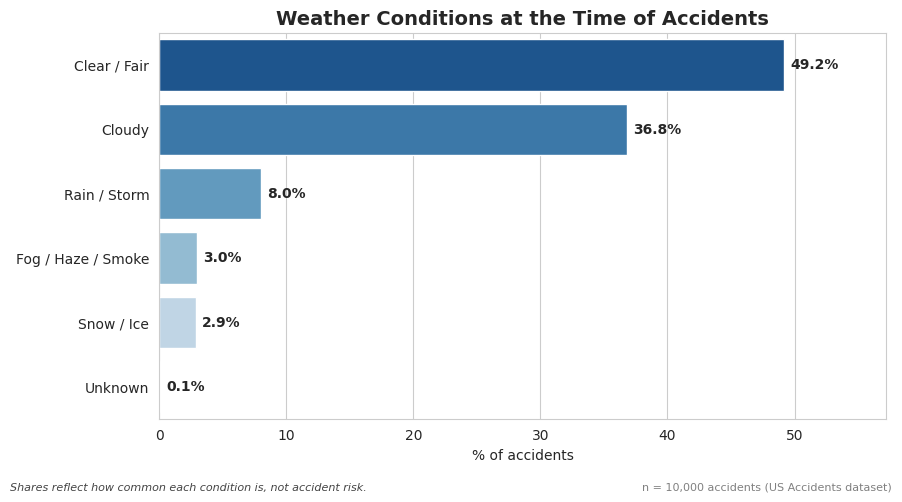

Saved output/weather_conditions.png


In [6]:
print("\n" + "=" * 50)
print("WEATHER")
print("=" * 50)

wg = df["weather_group"].value_counts()
wg_pct = (wg / wg.sum() * 100).round(1)
print("\nAccidents by weather group (%):\n", wg_pct)

plt.figure(figsize=(9, 5))
order = wg.index.tolist()
ax = sns.barplot(x=wg_pct.reindex(order).values, y=order, hue=order, palette="Blues_r", legend=False)
for i, v in enumerate(wg_pct.reindex(order).values):
    ax.text(v + 0.5, i, f"{v}%", va="center", fontweight="bold")
plt.title("Weather Conditions at the Time of Accidents", fontsize=14, fontweight="bold")
plt.xlabel("% of accidents")
plt.ylabel("")
plt.xlim(0, wg_pct.max() + 8)
add_footer(plt.gcf(), "Shares reflect how common each condition is, not accident risk.")
plt.tight_layout(rect=[0, 0.035, 1, 1])
plt.savefig("output/weather_conditions.png", dpi=150)
plt.show()
print("Saved output/weather_conditions.png")

## 5. Road Features & Severity (With Uncertainty)


ROAD FEATURES

% of accidents with a road feature nearby:
 Crossing          9.6
Traffic_Signal    9.1
Junction          7.8
Stop              2.9
Station           2.9
Amenity           1.3
Railway           0.8
Give_Way          0.3
dtype: float64


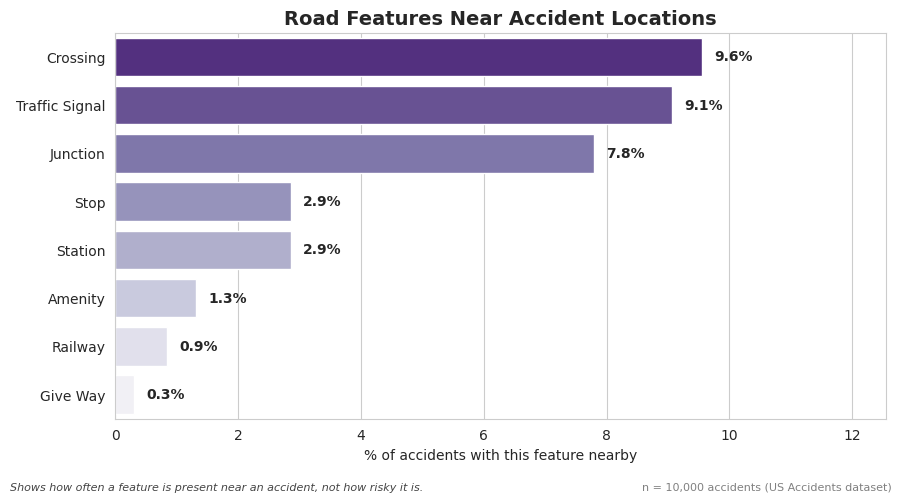

Saved output/road_features.png

Severe (3-4) share by road feature, with 95% CI:
       feature  present    n  severe_pct  lo   hi
      Junction    False 9221         4.9 4.5  5.3
      Junction     True  779         9.4 7.5 11.6
Traffic Signal    False 9094         5.0 4.6  5.5
Traffic Signal     True  906         7.3 5.8  9.2
      Crossing    False 9045         5.3 4.9  5.8
      Crossing     True  955         4.6 3.4  6.1
          Stop    False 9714         5.3 4.8  5.7
          Stop     True  286         4.5 2.7  7.6


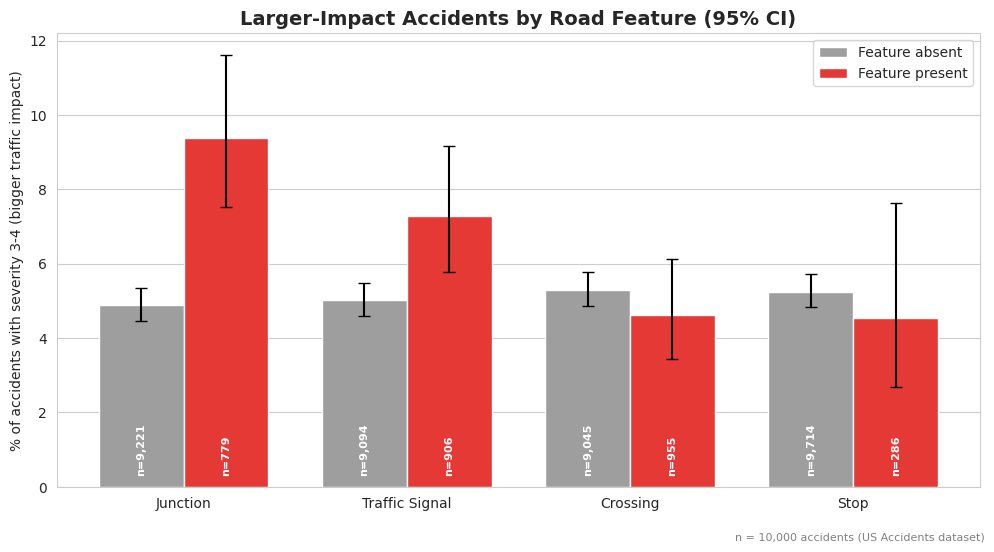

Saved output/severity_by_road_feature.png


In [7]:
print("\n" + "=" * 50)
print("ROAD FEATURES")
print("=" * 50)

# 5a. How often is each road feature present near an accident?
feat_pct = pd.Series({f: df[f].mean() * 100 for f in ROAD_FEATURES}).sort_values(ascending=False)
print("\n% of accidents with a road feature nearby:\n", feat_pct.round(1))

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=feat_pct.values, y=[f.replace("_", " ") for f in feat_pct.index],
                 hue=feat_pct.index, palette="Purples_r", legend=False)
for i, v in enumerate(feat_pct.values):
    ax.text(v + 0.2, i, f"{v:.1f}%", va="center", fontweight="bold")
plt.title("Road Features Near Accident Locations", fontsize=14, fontweight="bold")
plt.xlabel("% of accidents with this feature nearby")
plt.ylabel("")
plt.xlim(0, feat_pct.max() + 3)
add_footer(plt.gcf(), "Shows how often a feature is present near an accident, not how risky it is.")
plt.tight_layout(rect=[0, 0.035, 1, 1])
plt.savefig("output/road_features.png", dpi=150)
plt.show()
print("Saved output/road_features.png")


def wilson(k, n, z=1.96):
    """95% Wilson confidence interval for a proportion k/n."""
    p = k / n
    denom = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denom
    return centre - half, centre + half


# 5b. Severe share with vs without each major feature, with 95% CI
rows = []
for f in ["Junction", "Traffic_Signal", "Crossing", "Stop"]:
    for present in [False, True]:
        sub = df[df[f] == present]
        k, n = int(sub["severe"].sum()), len(sub)
        lo, hi = wilson(k, n)
        rows.append({"feature": f.replace("_", " "), "present": present,
                     "n": n, "severe_pct": k / n * 100, "lo": lo * 100, "hi": hi * 100})
sev_feat = pd.DataFrame(rows)
print("\nSevere (3-4) share by road feature, with 95% CI:")
print(sev_feat.round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5.5))
feats = sev_feat["feature"].unique()
x = np.arange(len(feats))
w = 0.38
for j, (present, color, label) in enumerate([(False, "#9E9E9E", "Feature absent"),
                                              (True, "#E53935", "Feature present")]):
    s = sev_feat[sev_feat["present"] == present].set_index("feature").loc[feats]
    yerr = [s["severe_pct"] - s["lo"], s["hi"] - s["severe_pct"]]
    ax.bar(x + (j - 0.5) * w, s["severe_pct"], w, yerr=yerr, capsize=4, color=color, label=label)
    for xi, (pct, n) in enumerate(zip(s["severe_pct"], s["n"])):
        ax.text(xi + (j - 0.5) * w, 0.3, f"n={n:,}", ha="center", va="bottom",
                fontsize=8, color="white", fontweight="bold", rotation=90)
ax.set_xticks(x)
ax.set_xticklabels(feats)
ax.set_ylabel("% of accidents with severity 3-4 (bigger traffic impact)")
ax.set_title("Larger-Impact Accidents by Road Feature (95% CI)", fontsize=14, fontweight="bold")
ax.legend()
ax.grid(axis="x", visible=False)
add_footer(fig)
plt.tight_layout(rect=[0, 0.035, 1, 1])
plt.savefig("output/severity_by_road_feature.png", dpi=150)
plt.show()
print("Saved output/severity_by_road_feature.png")

## 6. Severity By Time Of Day (With Uncertainty)


Severe (3-4) share by time of day, with 95% CI:
                bucket    n  severe_pct  lo  hi
        Night (12-6am) 1145         5.2 4.0 6.6
 Morning rush (6-10am) 1688         5.7 4.7 7.0
     Midday (10am-3pm) 2543         4.1 3.4 4.9
Afternoon rush (3-7pm) 2956         5.4 4.7 6.3
    Evening (7pm-12am) 1668         6.2 5.1 7.4


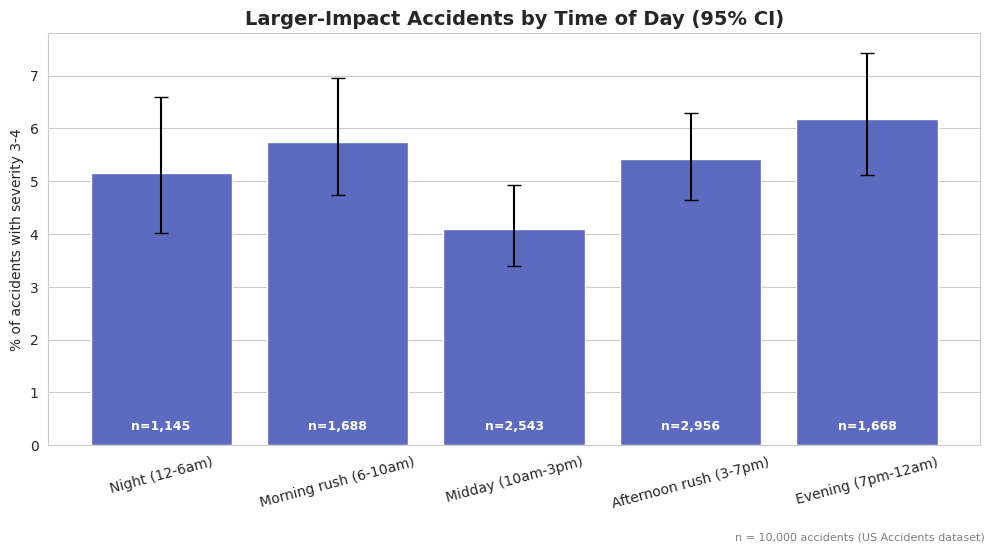

Saved output/severity_by_time_of_day.png


In [8]:
rows = []
for b in BUCKET_ORDER:
    sub = df[df["time_bucket"] == b]
    k, n = int(sub["severe"].sum()), len(sub)
    lo, hi = wilson(k, n)
    rows.append({"bucket": b, "n": n, "severe_pct": k / n * 100, "lo": lo * 100, "hi": hi * 100})
sev_time = pd.DataFrame(rows)
print("\nSevere (3-4) share by time of day, with 95% CI:")
print(sev_time.round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5.5))
yerr = [sev_time["severe_pct"] - sev_time["lo"], sev_time["hi"] - sev_time["severe_pct"]]
ax.bar(sev_time["bucket"], sev_time["severe_pct"], yerr=yerr, capsize=5, color="#5C6BC0")
for i, (pct, n) in enumerate(zip(sev_time["severe_pct"], sev_time["n"])):
    ax.text(i, 0.3, f"n={n:,}", ha="center", color="white", fontweight="bold", fontsize=9)
ax.set_ylabel("% of accidents with severity 3-4")
ax.set_title("Larger-Impact Accidents by Time of Day (95% CI)", fontsize=14, fontweight="bold")
plt.xticks(rotation=15)
ax.grid(axis="x", visible=False)
add_footer(fig)
plt.tight_layout(rect=[0, 0.035, 1, 1])
plt.savefig("output/severity_by_time_of_day.png", dpi=150)
plt.show()
print("Saved output/severity_by_time_of_day.png")

## 7. Hotspots


HOTSPOTS


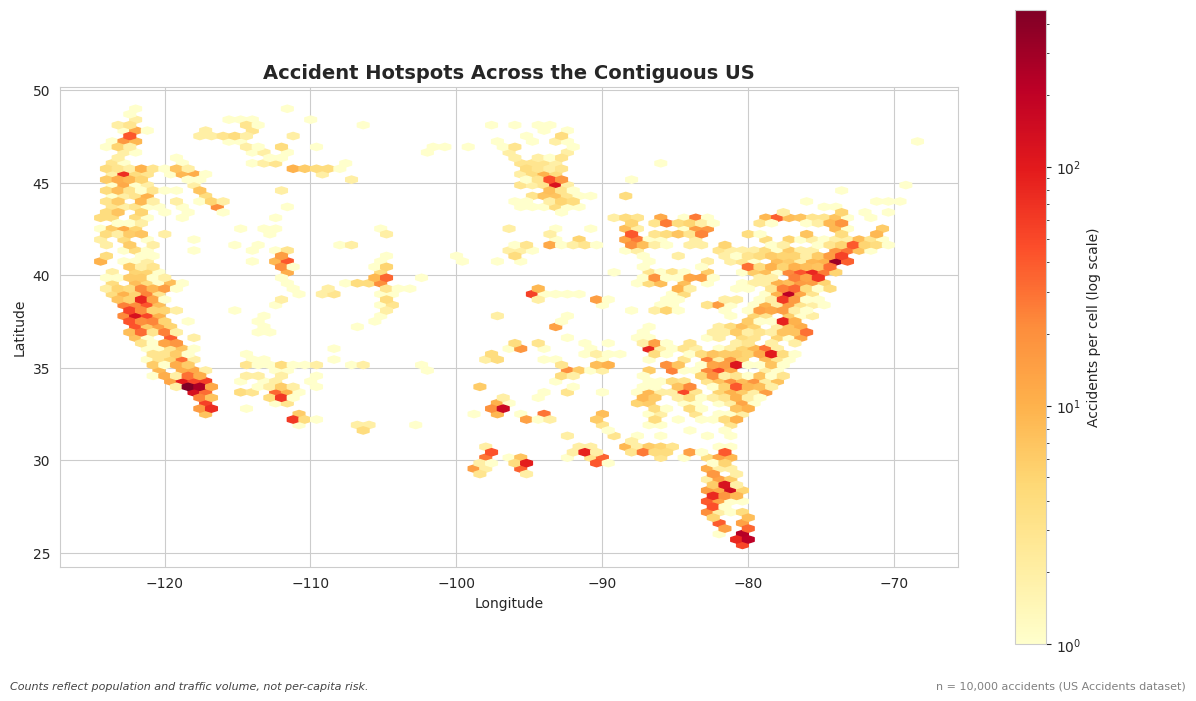

Saved output/hotspots_map.png

Top 5 states (share of accidents):
State
CA    25.1
FL    14.2
VA     5.1
TX     4.8
NY     4.7
Name: count, dtype: float64

Top 5 cities:
City         State
Miami        FL       381
Los Angeles  CA       231
Orlando      FL       205
Dallas       TX       143
Houston      TX       132
dtype: int64


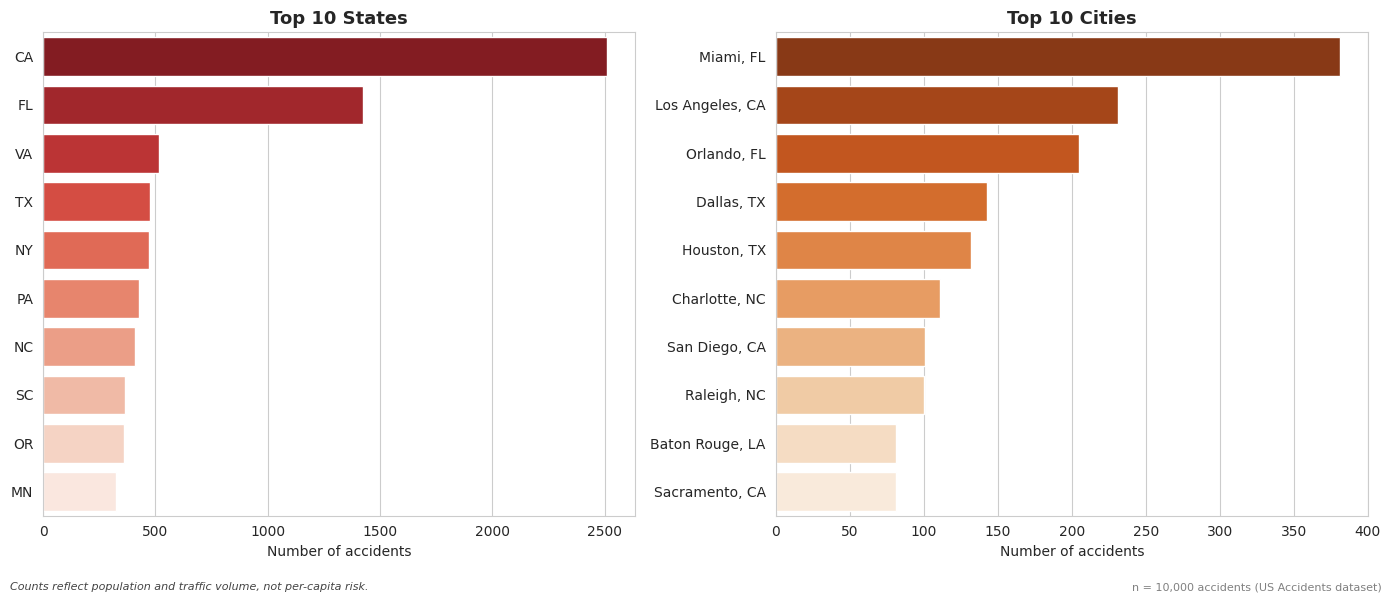

Saved output/top_states_cities.png


In [9]:
print("\n" + "=" * 50)
print("HOTSPOTS")
print("=" * 50)

fig, ax = plt.subplots(figsize=(12, 7))
hb = ax.hexbin(us["Start_Lng"], us["Start_Lat"], gridsize=70, bins="log",
               cmap="YlOrRd", mincnt=1)
ax.set_aspect(1 / np.cos(np.radians(38)))  # keep the US from looking stretched
ax.set_title("Accident Hotspots Across the Contiguous US", fontsize=14, fontweight="bold")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
fig.colorbar(hb, label="Accidents per cell (log scale)")
add_footer(fig, "Counts reflect population and traffic volume, not per-capita risk.")
plt.tight_layout(rect=[0, 0.035, 1, 1])
plt.savefig("output/hotspots_map.png", dpi=150)
plt.show()
print("Saved output/hotspots_map.png")

top_states = df["State"].value_counts().head(10)
top_cities = df.groupby(["City", "State"]).size().sort_values(ascending=False).head(10)
city_labels = [f"{c}, {s}" for c, s in top_cities.index]
print("\nTop 5 states (share of accidents):")
print((top_states.head(5) / len(df) * 100).round(1))
print("\nTop 5 cities:")
print(top_cities.head(5))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=top_states.values, y=top_states.index, hue=top_states.index,
            palette="Reds_r", legend=False, ax=axes[0])
axes[0].set_title("Top 10 States", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Number of accidents")
axes[0].set_ylabel("")
sns.barplot(x=top_cities.values, y=city_labels, hue=city_labels,
            palette="Oranges_r", legend=False, ax=axes[1])
axes[1].set_title("Top 10 Cities", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Number of accidents")
axes[1].set_ylabel("")
add_footer(fig, "Counts reflect population and traffic volume, not per-capita risk.")
plt.tight_layout(rect=[0, 0.035, 1, 1])
plt.savefig("output/top_states_cities.png", dpi=150)
plt.show()
print("Saved output/top_states_cities.png")

## 8. Sanity Checks On The Sample Itself

In [10]:
print("\n" + "=" * 50)
print("SAMPLE CHECKS")
print("=" * 50)
print(f"\nOverall share with severity 3-4: {df['severe'].mean() * 100:.1f}%")
print("\nSeverity share (%):\n", (df["Severity"].value_counts(normalize=True).sort_index() * 100).round(1))
print("\nAccidents per year:\n", df["Start_Time"].dt.year.value_counts().sort_index())
print("\nDone!")


SAMPLE CHECKS

Overall share with severity 3-4: 5.2%

Severity share (%):
 Severity
1     0.7
2    94.0
3     1.9
4     3.3
Name: proportion, dtype: float64

Accidents per year:
 Start_Time
2016      12
2017      29
2018      30
2019     561
2020    1785
2021    2909
2022    4028
2023     646
Name: count, dtype: int64

Done!


## Key findings
- **Time of day is the clearest pattern.** Busiest hour is 5pm (788 accidents); 29.6% of accidents fall between 3pm and 7pm vs. 11.5% between midnight and 6am. Weekdays show a small ~7-8am peak and a larger ~3-5pm peak; weekends are flatter (peak 3pm). Weekdays average 1,555 accidents/day vs. 1,114 on weekend days.
- **Weather:** Clear/Fair 49.2%, Cloudy 36.8%, Rain/Storm 8.0%, Fog/Haze/Smoke 3.0%, Snow/Ice 2.9%. *This is not a risk ranking* — clear weather is simply the most common.
- **Junctions** are the one clear signal for larger-impact accidents (severity 3-4): 9.4% vs. 4.9% elsewhere (95% CI 7.5-11.6% vs. 4.5-5.3%). Crossings and stop signs show no clear difference.
- **Time of day vs. impact:** differences are small (midday 4.1% to evening 6.2%) — a weak hint at most.
- **Hotspots:** clusters around Los Angeles, Florida, Texas cities, Atlanta and the Northeast corridor. These are counts, not per-capita risk.

## Limitations
1. **The sample is not representative.** 100% of rows come from one data source; 94.0% have severity 2 (the full dataset is reported to be nearer ~80%, unverified by me); 87.2% of rows are from 2020-2022. It was sampled after dropping every row with a missing value.
2. **Associations, not causes.** No exposure baseline exists for weather or road features.
3. **"Severity" means impact on traffic (delay), not injury.**
4. Weather categories are my own grouping of the raw strings.

---
*Dataset: US Accidents (Moosavi et al.), CC BY-NC-SA 4.0. Part of the Data Science Internship @ Prodigy InfoTech (Oct 2026)* #ProdigyInfoTech